In [1]:
# ============================================================
# UTS GRAF SAINS DATA
# Analisis Interaksi E-Commerce RetailRocket
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from neo4j import GraphDatabase
from getpass import getpass
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Library berhasil diimpor.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


Library berhasil diimpor.
Pandas: 3.0.6
NumPy: 2.5.4


In [2]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Documents" / "UTS-Graf-Sains-Data"

print("Folder proyek ditemukan:", PROJECT_DIR.exists())
print("Lokasi proyek:", PROJECT_DIR)
print("Dataset P1 ditemukan:", (PROJECT_DIR / "data" / "events_P1.csv").exists())
print("Dataset P2 ditemukan:", (PROJECT_DIR / "data" / "events_P2.csv").exists())

Folder proyek ditemukan: True
Lokasi proyek: /Users/annisaramadhani/Documents/UTS-Graf-Sains-Data
Dataset P1 ditemukan: True
Dataset P2 ditemukan: True


In [3]:
NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USERNAME = "neo4j"
NEO4J_DATABASE = "neo4j"

NEO4J_PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)

driver.verify_connectivity()

with driver.session(database=NEO4J_DATABASE) as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN count(r) AS total_relasi
    """)
    total_relasi = result.single()["total_relasi"]

print("Koneksi Neo4j berhasil!")
print(f"Total relasi dalam database: {total_relasi:,}")

Masukkan password Neo4j:  ········


Koneksi Neo4j berhasil!
Total relasi dalam database: 2,756,101


In [4]:

# Ambil interaksi periode P1 untuk membangun VSM
query_p1 = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period = 'P1'
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    type(r) AS event_type,
    count(r) AS event_count
ORDER BY visitor_id, item_id
"""

with driver.session(database=NEO4J_DATABASE) as session:
    result = session.run(query_p1)
    records = [record.data() for record in result]

df_p1 = pd.DataFrame(records)

print("Jumlah baris hasil query:", f"{len(df_p1):,}")
display(df_p1.head())

Jumlah baris hasil query: 1,521,057


,visitor_id,item_id,event_type,event_count
0,5,61396,VIEWED,1
1,7,139394,VIEWED,1
2,7,164941,VIEWED,1
3,7,226353,VIEWED,1
4,8,434230,VIEWED,1


In [5]:

# ============================================================
# VSM: MATRIKS INTERAKSI VISITOR-ITEM PERIODE P1
# ============================================================

# Bobot interaksi untuk implicit feedback
# VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5
event_weights = {
    "VIEWED": 1,
    "ADDED_TO_CART": 3,
    "BOUGHT": 5
}

df_p1["event_weight"] = df_p1["event_type"].map(event_weights)
df_p1["weighted_count"] = df_p1["event_weight"] * df_p1["event_count"]

# Gabungkan seluruh jenis interaksi pada pasangan visitor-item
df_interactions = (
    df_p1.groupby(["visitor_id", "item_id"], as_index=False)["weighted_count"]
    .sum()
)

# Petakan ID asli ke indeks matriks
visitor_ids = np.sort(df_interactions["visitor_id"].unique())
item_ids = np.sort(df_interactions["item_id"].unique())

visitor_to_idx = {vid: idx for idx, vid in enumerate(visitor_ids)}
item_to_idx = {iid: idx for idx, iid in enumerate(item_ids)}

rows = df_interactions["visitor_id"].map(visitor_to_idx).to_numpy()
cols = df_interactions["item_id"].map(item_to_idx).to_numpy()
values = df_interactions["weighted_count"].to_numpy(dtype=np.float32)

# Matriks sparse Visitor x Item
X = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.float32
)

print("Jumlah visitor:", f"{len(visitor_ids):,}")
print("Jumlah item:", f"{len(item_ids):,}")
print("Jumlah pasangan visitor-item:", f"{X.nnz:,}")
print("Bentuk matriks VSM:", X.shape)
print("Jumlah nilai nonzero:", f"{X.nnz:,}")
print("Kepadatan matriks:", f"{X.nnz / (X.shape[0] * X.shape[1]):.8%}")

Jumlah visitor: 962,528
Jumlah item: 199,689
Jumlah pasangan visitor-item: 1,472,639
Bentuk matriks VSM: (962528, 199689)
Jumlah nilai nonzero: 1,472,639
Kepadatan matriks: 0.00076618%


In [6]:

# ============================================================
# PROYEKSI USER DAN ITEM
# ============================================================

# Bentuk proyeksi secara matematis:
# User projection: X @ X.T -> visitor x visitor
# Item projection: X.T @ X -> item x item
# Tidak dihitung penuh karena ukurannya sangat besar.

print("Matriks interaksi X:", X.shape)
print("Bentuk proyeksi user:", (X.shape[0], X.shape[0]))
print("Bentuk proyeksi item:", (X.shape[1], X.shape[1]))

# Pilih visitor dengan interaksi terbanyak untuk visualisasi
visitor_activity = np.asarray(X.getnnz(axis=1)).ravel()
top_n_users = 100

top_user_idx = np.argsort(visitor_activity)[-top_n_users:]
X_user_sample = X[top_user_idx, :]

print("\nSubset untuk visualisasi:")
print("Jumlah visitor terpilih:", X_user_sample.shape[0])
print("Jumlah item pada subset:", X_user_sample.shape[1])
print("Jumlah interaksi nonzero:", f"{X_user_sample.nnz:,}")

Matriks interaksi X: (962528, 199689)
Bentuk proyeksi user: (962528, 962528)
Bentuk proyeksi item: (199689, 199689)

Subset untuk visualisasi:
Jumlah visitor terpilih: 100
Jumlah item pada subset: 199689
Jumlah interaksi nonzero: 47,021


User similarity matrix: (100, 100)
Item similarity matrix: (100, 100)

Graf user:
Node: 100
Edge: 248

Graf item:
Node: 100
Edge: 230


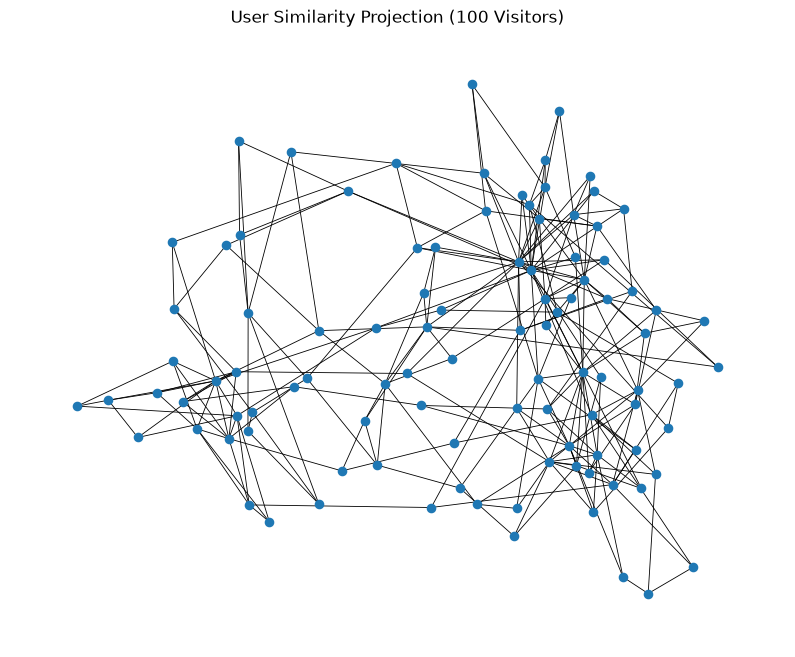

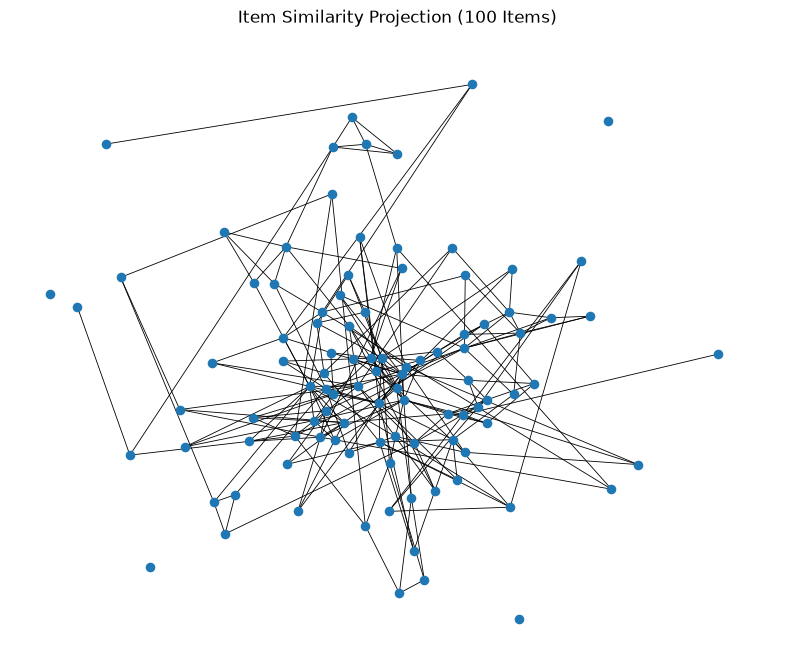

In [7]:

# ============================================================
# COSINE SIMILARITY: USER PROJECTION DAN ITEM PROJECTION
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# ---------- A. USER PROJECTION ----------
# Ambil 100 visitor dengan jumlah interaksi unik terbanyak
user_similarity = cosine_similarity(X_user_sample, dense_output=True)

user_ids_sample = visitor_ids[top_user_idx]

print("User similarity matrix:", user_similarity.shape)

# ---------- B. ITEM PROJECTION ----------
# Pilih 100 item dengan jumlah visitor unik terbanyak
item_activity = np.asarray(X.getnnz(axis=0)).ravel()
top_n_items = 100
top_item_idx = np.argsort(item_activity)[-top_n_items:]

X_item_sample = X[:, top_item_idx].T.tocsr()
item_similarity = cosine_similarity(X_item_sample, dense_output=True)

item_ids_sample = item_ids[top_item_idx]

print("Item similarity matrix:", item_similarity.shape)

# ---------- C. FUNGSI MEMBANGUN GRAF ----------
def build_similarity_graph(similarity_matrix, node_ids, top_k=3):
    G = nx.Graph()
    G.add_nodes_from(node_ids.tolist())

    n = len(node_ids)
    for i in range(n):
        scores = similarity_matrix[i].copy()
        scores[i] = -1  # hindari hubungan node dengan dirinya sendiri

        neighbors = np.argsort(scores)[-top_k:]
        for j in neighbors:
            weight = float(scores[j])
            if weight > 0:
                G.add_edge(node_ids[i], node_ids[j], weight=weight)

    return G

G_user = build_similarity_graph(user_similarity, user_ids_sample, top_k=3)
G_item = build_similarity_graph(item_similarity, item_ids_sample, top_k=3)

print("\nGraf user:")
print("Node:", G_user.number_of_nodes())
print("Edge:", G_user.number_of_edges())

print("\nGraf item:")
print("Node:", G_item.number_of_nodes())
print("Edge:", G_item.number_of_edges())

# ---------- D. VISUALISASI GRAF USER ----------
plt.figure(figsize=(10, 8))
pos_user = nx.spring_layout(G_user, seed=42)
nx.draw_networkx(
    G_user, pos_user,
    node_size=35,
    with_labels=False,
    width=0.6
)
plt.title("User Similarity Projection (100 Visitors)")
plt.axis("off")
plt.show()

# ---------- E. VISUALISASI GRAF ITEM ----------
plt.figure(figsize=(10, 8))
pos_item = nx.spring_layout(G_item, seed=42)
nx.draw_networkx(
    G_item, pos_item,
    node_size=35,
    with_labels=False,
    width=0.6
)
plt.title("Item Similarity Projection (100 Items)")
plt.axis("off")
plt.show()

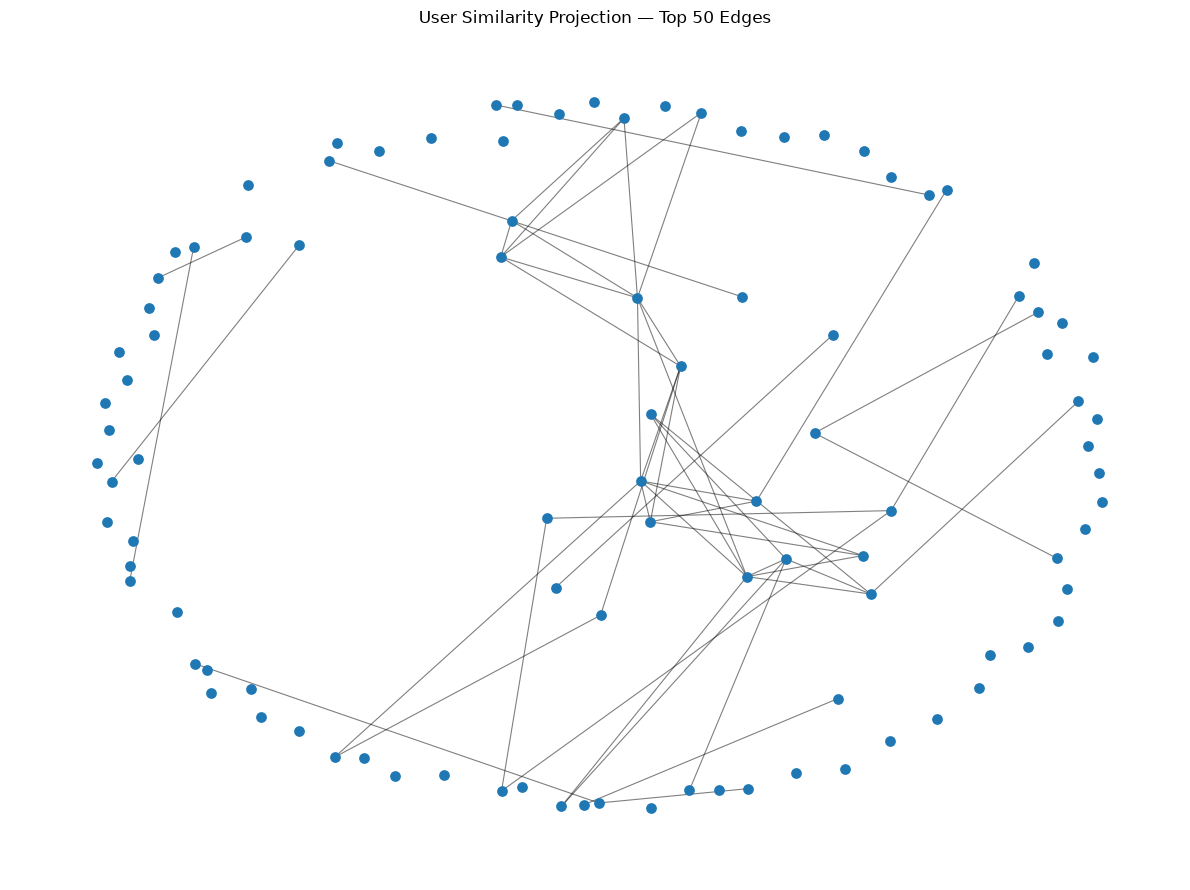

Jumlah node: 100
Jumlah edge: 50


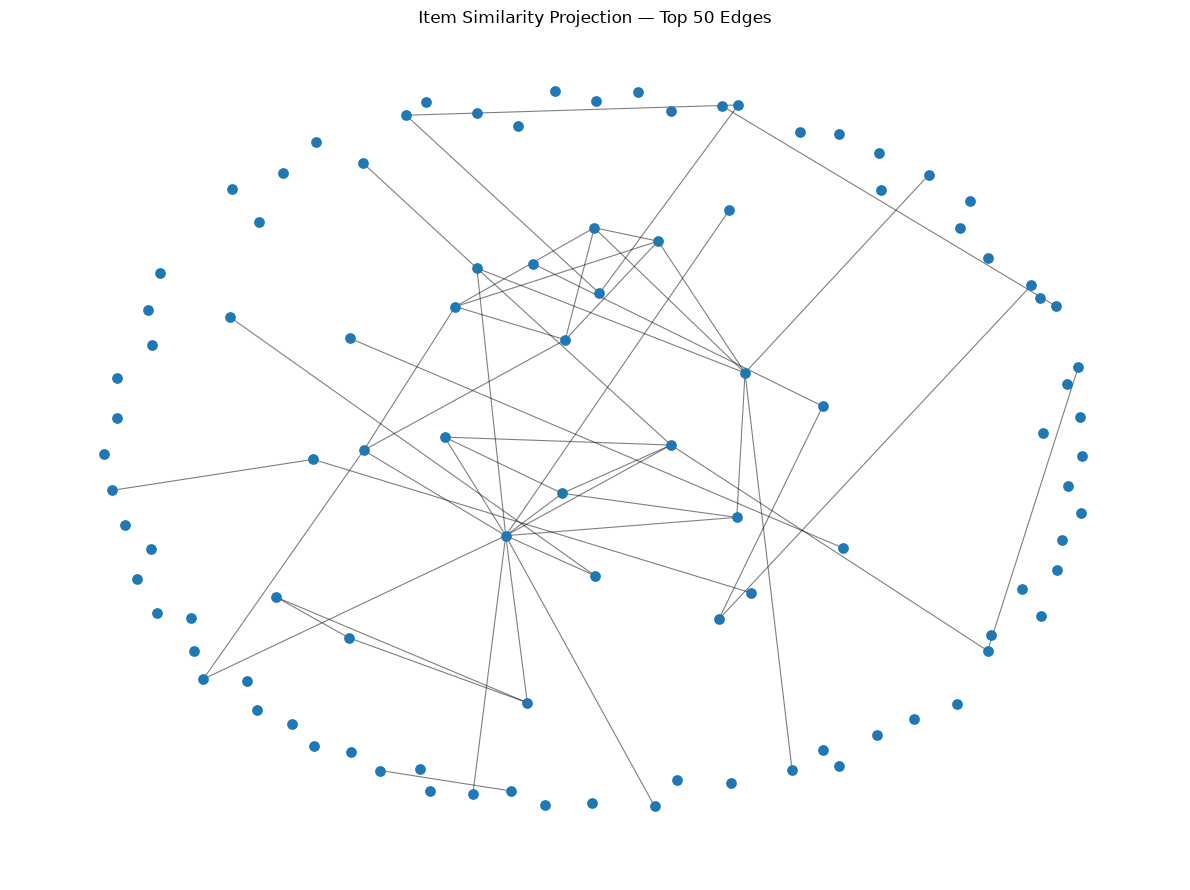

Jumlah node: 100
Jumlah edge: 50


In [8]:

# Visualisasi graf dengan 50 edge similarity terkuat

def plot_top_edges(G, title, max_edges=50):
    G_plot = nx.Graph()
    G_plot.add_nodes_from(G.nodes(data=True))

    strongest_edges = sorted(
        G.edges(data=True),
        key=lambda edge: edge[2]["weight"],
        reverse=True
    )[:max_edges]

    G_plot.add_edges_from(strongest_edges)

    plt.figure(figsize=(12, 9))
    pos = nx.spring_layout(G_plot, seed=42, k=0.8, iterations=100)

    nx.draw_networkx_nodes(
        G_plot, pos,
        node_size=45
    )
    nx.draw_networkx_edges(
        G_plot, pos,
        width=0.8,
        alpha=0.5
    )

    plt.title(f"{title} — Top {len(strongest_edges)} Edges")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("Jumlah node:", G_plot.number_of_nodes())
    print("Jumlah edge:", G_plot.number_of_edges())

plot_top_edges(G_user, "User Similarity Projection")
plot_top_edges(G_item, "Item Similarity Projection")

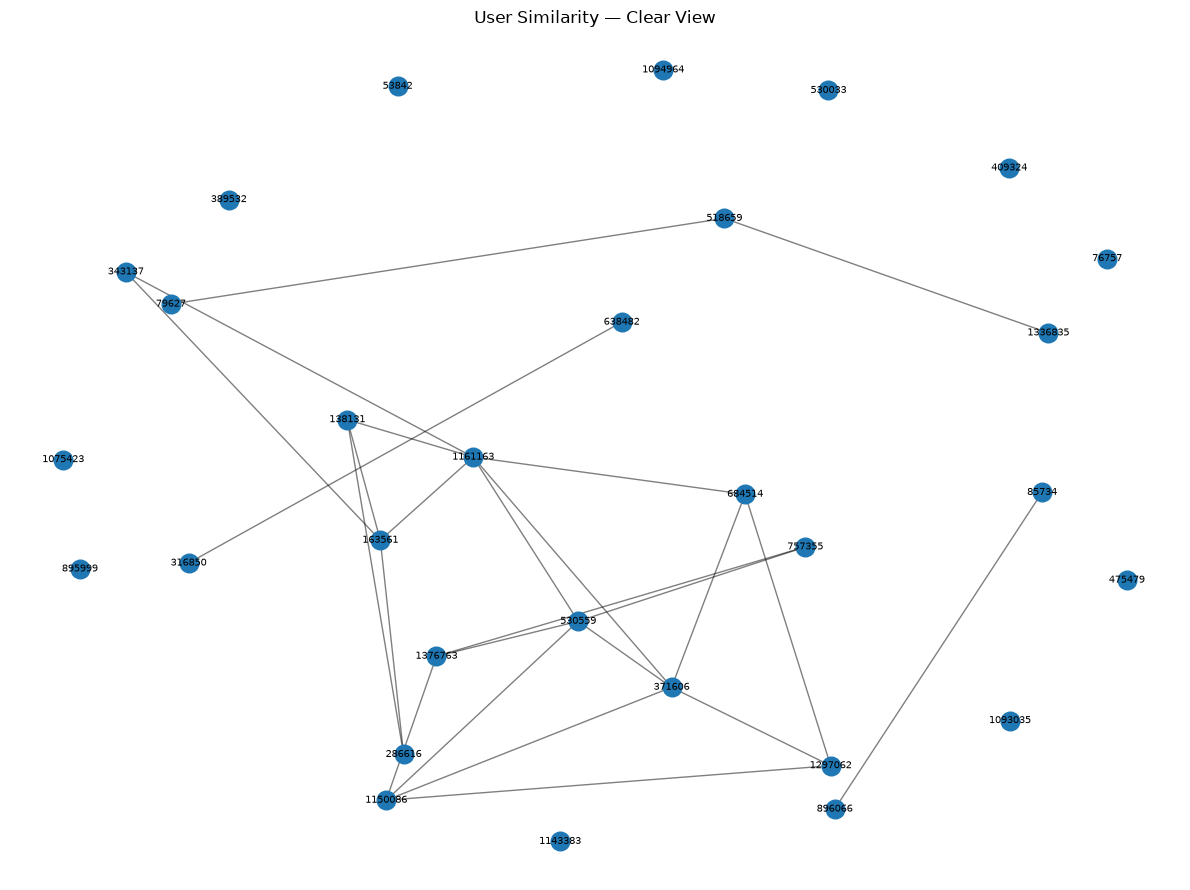

Node: 30
Edge: 25


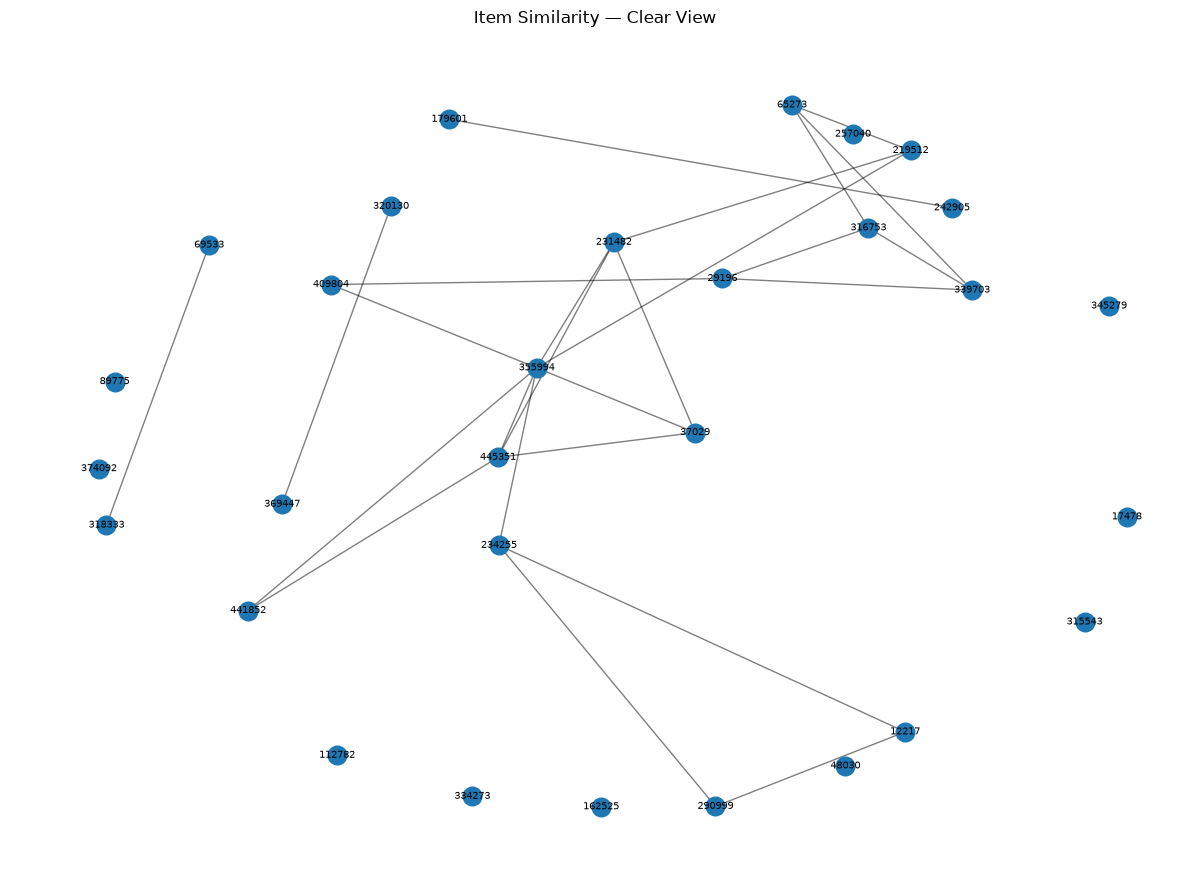

Node: 30
Edge: 25


In [9]:

def plot_clear_graph(G, title, max_nodes=30, max_edges=25):
    # Pilih node dengan derajat tertinggi
    selected_nodes = sorted(
        G.degree(),
        key=lambda x: x[1],
        reverse=True
    )[:max_nodes]

    selected_ids = [node for node, degree in selected_nodes]
    H = G.subgraph(selected_ids).copy()

    # Ambil edge dengan bobot tertinggi
    strongest_edges = sorted(
        H.edges(data=True),
        key=lambda edge: edge[2]["weight"],
        reverse=True
    )[:max_edges]

    H_plot = nx.Graph()
    H_plot.add_nodes_from(H.nodes())
    H_plot.add_edges_from(strongest_edges)

    # Atur jarak antarnode lebih renggang
    pos = nx.spring_layout(
        H_plot,
        seed=42,
        k=2.0,
        iterations=200,
        weight="weight"
    )

    plt.figure(figsize=(12, 9))
    nx.draw_networkx_nodes(
        H_plot, pos,
        node_size=180
    )
    nx.draw_networkx_edges(
        H_plot, pos,
        width=1.0,
        alpha=0.5
    )
    nx.draw_networkx_labels(
        H_plot, pos,
        font_size=7
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("Node:", H_plot.number_of_nodes())
    print("Edge:", H_plot.number_of_edges())

plot_clear_graph(G_user, "User Similarity — Clear View")
plot_clear_graph(G_item, "Item Similarity — Clear View")

In [10]:

# Perbandingan ukuran proyeksi dan jumlah edge pada graf awal

projection_comparison = pd.DataFrame([
    {
        "projection": "User",
        "nodes": G_user.number_of_nodes(),
        "edges": G_user.number_of_edges(),
        "similarity_matrix_shape": str(user_similarity.shape)
    },
    {
        "projection": "Item",
        "nodes": G_item.number_of_nodes(),
        "edges": G_item.number_of_edges(),
        "similarity_matrix_shape": str(item_similarity.shape)
    }
])

display(projection_comparison)

,projection,nodes,edges,similarity_matrix_shape
0,User,100,248,"(100, 100)"
1,Item,100,230,"(100, 100)"


In [11]:

# ============================================================
# DATA TESTING: PERIODE P2
# ============================================================

query_p2 = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period = 'P2'
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    type(r) AS event_type,
    count(r) AS event_count
"""

with driver.session(database=NEO4J_DATABASE) as session:
    result = session.run(query_p2)
    records_p2 = [record.data() for record in result]

df_p2 = pd.DataFrame(records_p2)

print("Jumlah baris interaksi P2:", f"{len(df_p2):,}")
print("Jumlah visitor unik P2:", f"{df_p2['visitor_id'].nunique():,}")
print("Jumlah item unik P2:", f"{df_p2['item_id'].nunique():,}")

display(df_p2.head())

Jumlah baris interaksi P2: 701,402
Jumlah visitor unik P2: 475,320
Jumlah item unik P2: 142,759


,visitor_id,item_id,event_type,event_count
0,87679,355908,VIEWED,1
1,27375,355908,VIEWED,1
2,137170,355908,VIEWED,11
3,1070521,355908,VIEWED,1
4,466806,355908,VIEWED,2


In [12]:

# ============================================================
# PERSIAPAN KNN DAN DATA EVALUASI
# ============================================================

from sklearn.neighbors import NearestNeighbors

# Bobot aktivitas dibuat konsisten dengan data training P1
df_p2["event_weight"] = df_p2["event_type"].map(event_weights)
df_p2["weighted_count"] = df_p2["event_weight"] * df_p2["event_count"]

# Gabungkan interaksi P2 per visitor-item
df_test = (
    df_p2.groupby(["visitor_id", "item_id"], as_index=False)["weighted_count"]
    .sum()
)

# Target evaluasi hanya item yang dikenal dalam katalog training
# Item baru P2 tidak dapat direkomendasikan oleh model berbasis X ini
train_item_set = set(item_ids.tolist())
df_test_known = df_test[df_test["item_id"].isin(train_item_set)].copy()

# Visitor yang memiliki riwayat training P1 dan target P2
train_visitor_set = set(visitor_ids.tolist())
test_visitor_set = set(df_test_known["visitor_id"].unique())
eligible_visitors = np.array(
    sorted(train_visitor_set.intersection(test_visitor_set))
)

print("Visitor yang memenuhi syarat evaluasi:", f"{len(eligible_visitors):,}")
print("Interaksi target P2 dengan item dikenal:", f"{len(df_test_known):,}")

# Ambil sampel visitor secara reproducible
rng = np.random.default_rng(42)
n_eval = min(100, len(eligible_visitors))
eval_users = rng.choice(eligible_visitors, size=n_eval, replace=False)

print("Jumlah visitor sampel evaluasi:", n_eval)

# Fit KNN pada matriks interaksi P1 yang sparse
knn = NearestNeighbors(
    n_neighbors=6,       # 1 tetangga adalah dirinya sendiri; 5 lainnya dipakai
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
knn.fit(X)

print("Model KNN berhasil dilatih.")

Visitor yang memenuhi syarat evaluasi: 28,398
Interaksi target P2 dengan item dikenal: 618,057
Jumlah visitor sampel evaluasi: 100
Model KNN berhasil dilatih.


In [14]:

def recommend_top5(user_id, k_neighbors=5, top_n=5):
    uidx = visitor_index[user_id]

    distances, indices = knn.kneighbors(
        X[uidx],
        n_neighbors=k_neighbors + 1
    )

    # Ambil 5 tetangga terdekat, tanpa visitor itu sendiri
    neighbors = []
    for dist, idx in zip(distances[0], indices[0]):
        if idx != uidx:
            neighbors.append((idx, max(0.0, 1.0 - float(dist))))
        if len(neighbors) == k_neighbors:
            break

    scores = defaultdict(float)
    seen = user_items[user_id]

    # X adalah matriks Visitor × Item.
    # Baris X[neighbor_idx] berisi item milik tetangga.
    for neighbor_idx, similarity in neighbors:
        start = X.indptr[neighbor_idx]
        end = X.indptr[neighbor_idx + 1]

        neighbor_item_indices = X.indices[start:end]
        neighbor_values = X.data[start:end]

        for item_idx, value in zip(neighbor_item_indices, neighbor_values):
            item_id = int(item_ids[item_idx])

            # Hindari merekomendasikan item yang sudah dilihat
            if item_id not in seen:
                scores[item_id] += similarity * float(value)

    ranked = sorted(
        scores.items(),
        key=lambda x: (-x[1], x[0])
    )

    return [item_id for item_id, score in ranked[:top_n]]

In [15]:

print("Cek fungsi rekomendasi")

print("Jumlah visitor evaluasi:", len(eval_users))
print("Bentuk matriks X:", X.shape)
print("Jumlah baris hasil KNN:", knn.n_samples_fit_)

test_user = int(eval_users[0])
print("Visitor uji:", test_user)

test_recommendations = recommend_top5(
    test_user,
    k_neighbors=5,
    top_n=5
)

print("Rekomendasi:", test_recommendations)

Cek fungsi rekomendasi
Jumlah visitor evaluasi: 100
Bentuk matriks X: (962528, 199689)
Jumlah baris hasil KNN: 962528
Visitor uji: 612785
Rekomendasi: []


In [16]:

# DIAGNOSTIK KNN UNTUK SATU VISITOR

test_user = int(eval_users[0])
uidx = visitor_index[test_user]

distances, indices = knn.kneighbors(
    X[uidx],
    n_neighbors=6
)

print("Visitor:", test_user)
print("Indeks visitor:", uidx)
print("Indeks tetangga:", indices[0])
print("Jarak cosine:", distances[0])
print("Jumlah item pada visitor:", X[uidx].nnz)

for dist, idx in zip(distances[0], indices[0]):
    print(
        "Neighbor index:", int(idx),
        "| Sama dengan target:", int(idx) == uidx,
        "| Item yang dimiliki:", int(X[idx].nnz),
        "| Similarity:", round(1 - float(dist), 6)
    )

Visitor: 612785
Indeks visitor: 419278
Indeks tetangga: [419278 850376 588613 960370 771791 713014]
Jarak cosine: [0.         0.07152331 0.07152331 0.07152331 0.07152331 0.07152331]
Jumlah item pada visitor: 2
Neighbor index: 419278 | Sama dengan target: True | Item yang dimiliki: 2 | Similarity: 1.0
Neighbor index: 850376 | Sama dengan target: False | Item yang dimiliki: 1 | Similarity: 0.928477
Neighbor index: 588613 | Sama dengan target: False | Item yang dimiliki: 1 | Similarity: 0.928477
Neighbor index: 960370 | Sama dengan target: False | Item yang dimiliki: 1 | Similarity: 0.928477
Neighbor index: 771791 | Sama dengan target: False | Item yang dimiliki: 1 | Similarity: 0.928477
Neighbor index: 713014 | Sama dengan target: False | Item yang dimiliki: 1 | Similarity: 0.928477


In [17]:

# Cek item target dan item dari 5 tetangga terdekat

test_user = int(eval_users[0])
uidx = visitor_index[test_user]

distances, indices = knn.kneighbors(
    X[uidx],
    n_neighbors=6
)

target_items = set(
    item_ids[X[uidx].indices].tolist()
)

print("Visitor target:", test_user)
print("Item target pada P1:", target_items)
print("Jumlah item target:", len(target_items))
print()

for dist, idx in zip(distances[0][1:], indices[0][1:]):
    neighbor_user = int(visitor_ids[idx])
    neighbor_items = set(item_ids[X[idx].indices].tolist())

    print("Neighbor:", neighbor_user)
    print("Similarity:", round(1 - float(dist), 6))
    print("Item tetangga:", neighbor_items)
    print("Item baru:", neighbor_items - target_items)
    print("-" * 40)

Visitor target: 612785
Item target pada P1: {174665, 203594}
Jumlah item target: 2

Neighbor: 1243210
Similarity: 0.928477
Item tetangga: {174665}
Item baru: set()
----------------------------------------
Neighbor: 860802
Similarity: 0.928477
Item tetangga: {174665}
Item baru: set()
----------------------------------------
Neighbor: 1404414
Similarity: 0.928477
Item tetangga: {174665}
Item baru: set()
----------------------------------------
Neighbor: 1128740
Similarity: 0.928477
Item tetangga: {174665}
Item baru: set()
----------------------------------------
Neighbor: 1042632
Similarity: 0.928477
Item tetangga: {174665}
Item baru: set()
----------------------------------------


In [18]:

def recommend_top5(user_id, k_neighbors=5, top_n=5):
    uidx = visitor_index[user_id]

    # Cari lebih banyak tetangga agar peluang menemukan item baru meningkat
    n_search = min(101, X.shape[0])
    distances, indices = knn.kneighbors(
        X[uidx],
        n_neighbors=n_search
    )

    candidates = []
    for dist, idx in zip(distances[0], indices[0]):
        if idx == uidx:
            continue

        similarity = max(0.0, 1.0 - float(dist))
        if similarity > 0:
            candidates.append((int(idx), similarity))

    seen = user_items[user_id]
    scores = defaultdict(float)
    neighbors_used = 0

    # Gunakan maksimal k_neighbors tetangga yang menyumbang item baru
    for neighbor_idx, similarity in candidates:
        start = X.indptr[neighbor_idx]
        end = X.indptr[neighbor_idx + 1]

        neighbor_item_indices = X.indices[start:end]
        neighbor_values = X.data[start:end]

        new_items = []
        for item_idx, value in zip(neighbor_item_indices, neighbor_values):
            item_id = int(item_ids[item_idx])
            if item_id not in seen:
                new_items.append((item_id, float(value)))

        if not new_items:
            continue

        neighbors_used += 1
        for item_id, value in new_items:
            scores[item_id] += similarity * value

        if neighbors_used >= k_neighbors:
            break

    ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))
    recommendations = [item_id for item_id, score in ranked[:top_n]]

    return recommendations

In [19]:
test_user = int(eval_users[0])

print("Visitor:", test_user)
print("Item yang sudah dilihat:", user_items[test_user])
print("Rekomendasi Top-5:", recommend_top5(test_user, k_neighbors=5, top_n=5))

Visitor: 612785
Item yang sudah dilihat: {174665, 203594}
Rekomendasi Top-5: [426489, 68255, 128051, 129705, 160522]


In [20]:

# Evaluasi rekomendasi untuk 100 visitor

evaluation_rows = []
start_time = time.time()

for user_id in eval_users:
    user_id = int(user_id)

    recommendations = recommend_top5(
        user_id,
        k_neighbors=5,
        top_n=5
    )

    relevant = test_relevant[user_id]

    evaluation_rows.append({
        "visitor_id": user_id,
        "num_relevant_p2": len(relevant),
        "recommendations": recommendations,
        "Hit@5": hit_at_k(recommendations, relevant, 5),
        "NDCG@5": ndcg_at_k(recommendations, relevant, 5)
    })

df_evaluation = pd.DataFrame(evaluation_rows)

print(f"Waktu evaluasi: {time.time() - start_time:.2f} detik")
print("Jumlah visitor dievaluasi:", len(df_evaluation))
print(f"Rata-rata Hit@5: {df_evaluation['Hit@5'].mean():.4f}")
print(f"Rata-rata NDCG@5: {df_evaluation['NDCG@5'].mean():.4f}")

display(df_evaluation.head(10))

Waktu evaluasi: 2.88 detik
Jumlah visitor dievaluasi: 100
Rata-rata Hit@5: 0.0100
Rata-rata NDCG@5: 0.0021


,visitor_id,num_relevant_p2,recommendations,Hit@5,NDCG@5
0,612785,1,"[426489, 68255, 128051, 129705, 160522]",0,0.0
1,1324345,6,"[287279, 300823, 105933, 373810, 409791]",0,0.0
2,941028,1,"[330506, 180989, 89369, 340238, 37218]",0,0.0
3,655482,1,"[80134, 392661, 173313, 398134, 140532]",0,0.0
4,630574,1,"[146855, 356029, 377882, 191593, 177303]",0,0.0
5,1097077,3,"[236416, 251368, 352723, 68000, 70846]",0,0.0
6,214944,1,"[457228, 187132, 459848, 1447, 3858]",0,0.0
7,454127,1,[],0,0.0
8,230648,1,[],0,0.0
9,1007484,3,"[75033, 93382, 238650, 56477, 13855]",0,0.0


In [21]:

# Ringkasan evaluasi KNN

print("Total visitor dievaluasi:", len(df_evaluation))
print("Rekomendasi kosong:", (df_evaluation["recommendations"].str.len() == 0).sum())
print("Visitor dengan Hit@5 = 1:", int(df_evaluation["Hit@5"].sum()))
print("Rata-rata Hit@5:", round(df_evaluation["Hit@5"].mean(), 4))
print("Rata-rata NDCG@5:", round(df_evaluation["NDCG@5"].mean(), 4))

print("\nVisitor yang berhasil mendapat Hit@5:")
display(
    df_evaluation[df_evaluation["Hit@5"] == 1][
        ["visitor_id", "num_relevant_p2", "recommendations", "Hit@5", "NDCG@5"]
    ]
)

print("\nContoh rekomendasi untuk visitor pertama:")
display(df_evaluation.head(1))

Total visitor dievaluasi: 100
Rekomendasi kosong: 14
Visitor dengan Hit@5 = 1: 1
Rata-rata Hit@5: 0.01
Rata-rata NDCG@5: 0.0021

Visitor yang berhasil mendapat Hit@5:


,visitor_id,num_relevant_p2,recommendations,Hit@5,NDCG@5
27,265485,5,"[213140, 334575, 3051, 24250, 37416]",1,0.213986



Contoh rekomendasi untuk visitor pertama:


,visitor_id,num_relevant_p2,recommendations,Hit@5,NDCG@5
0,612785,1,"[426489, 68255, 128051, 129705, 160522]",0,0.0


In [22]:

# Menampilkan 3 item rekomendasi untuk visitor terpilih

selected_user = 612785

recommendations = recommend_top5(
    selected_user,
    k_neighbors=5,
    top_n=5
)

top_3_recommendations = recommendations[:3]

print("Visitor ID:", selected_user)
print("Item yang sudah dilihat pada P1:", sorted(user_items[selected_user]))
print("Tiga item rekomendasi:", top_3_recommendations)
print("Jumlah rekomendasi yang dihasilkan:", len(recommendations))

Visitor ID: 612785
Item yang sudah dilihat pada P1: [174665, 203594]
Tiga item rekomendasi: [426489, 68255, 128051]
Jumlah rekomendasi yang dihasilkan: 5


In [24]:

top5_query = """
MATCH (source:Visitor {visitorId: $reference_id})
      -[r:SIMILAR_TO]->(target:Visitor)
RETURN
    source.visitorId AS reference_visitor,
    target.visitorId AS similar_visitor,
    r.similarity AS similarity,
    r.method AS method,
    r.period AS period
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database=NEO4J_DATABASE) as session:
    result = session.run(
        top5_query,
        reference_id=612785
    )
    df_top5_similar = pd.DataFrame(
        [record.data() for record in result]
    )

display(df_top5_similar)

,reference_visitor,similar_visitor,similarity,method,period
0,612785,1404414,0.928477,KNN cosine,P1
1,612785,1243210,0.928477,KNN cosine,P1
2,612785,1042632,0.928477,KNN cosine,P1
3,612785,860802,0.928477,KNN cosine,P1
4,612785,1128740,0.928477,KNN cosine,P1


## Kesimpulan

Berdasarkan analisis yang telah dilakukan menggunakan dataset RetailRocket, saya berhasil membangun dan menganalisis graf interaksi antara pengguna (*Visitor*) dan produk (*Item*) pada dua periode waktu, yaitu P1 dan P2. Dari hasil pengolahan data, periode P1 memiliki 1.899.029 relasi interaksi, sedangkan periode P2 memiliki 857.072 relasi interaksi. Interaksi tersebut terdiri dari `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` yang menggambarkan aktivitas pengguna terhadap produk.

Pada tahap eksplorasi data, saya mengubah interaksi pengguna menjadi matriks interaksi berbobot dengan memberikan bobot 1 untuk `VIEWED`, 3 untuk `ADDED_TO_CART`, dan 5 untuk `BOUGHT`. Matriks ini kemudian digunakan untuk menganalisis kemiripan antar pengguna dan antar produk menggunakan cosine similarity. Hasilnya divisualisasikan dalam bentuk graf menggunakan NetworkX agar hubungan kemiripan yang terbentuk dapat diamati dengan lebih mudah.

Selanjutnya, saya menerapkan metode K-Nearest Neighbors (KNN) untuk menghasilkan rekomendasi produk berdasarkan kemiripan pola interaksi pengguna. Evaluasi dilakukan menggunakan data pada periode P2 dengan metrik Hit@5 dan NDCG@5. Dari pengujian terhadap 100 pengguna, diperoleh rata-rata Hit@5 sebesar 0,0100 dan NDCG@5 sebesar 0,0021. Hasil tersebut menunjukkan bahwa rekomendasi yang dihasilkan masih belum optimal dalam menemukan produk yang relevan dengan interaksi pengguna pada periode pengujian. Oleh karena itu, metode rekomendasi ini masih dapat dikembangkan, misalnya dengan mengevaluasi pemilihan tetangga terdekat dan cara pemberian skor pada produk.

Selain menghasilkan rekomendasi, saya juga menghitung lima pengguna yang memiliki tingkat kemiripan tertinggi dengan pengguna referensi menggunakan cosine similarity berbasis KNN. Hasil kemiripan tersebut disimpan ke dalam Neo4j melalui relasi `SIMILAR_TO` dan diperiksa kembali menggunakan query Cypher. Dengan demikian, hasil perhitungan yang sebelumnya dilakukan di Python dapat disimpan dan ditelusuri kembali melalui graph database.

Melalui pengerjaan ini, saya memperoleh pemahaman yang lebih baik mengenai penggunaan graph database untuk merepresentasikan interaksi pengguna dan produk, pembentukan matriks interaksi, analisis kemiripan, serta penerapan KNN untuk sistem rekomendasi. Saya juga memahami bahwa keberhasilan membangun graf dan menghasilkan rekomendasi belum tentu menunjukkan bahwa rekomendasi tersebut sudah akurat. Oleh karena itu, evaluasi menggunakan data pengujian dan metrik yang sesuai menjadi bagian penting untuk mengetahui sejauh mana sistem rekomendasi dapat memberikan hasil yang relevan.